In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pointbiserialr

df = pd.read_csv("heart.csv")

print(df.head())

C:\Users\yusuf\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


  HeartDisease    BMI Smoking AlcoholDrinking Stroke  PhysicalHealth  \
0           No  16.60     Yes              No     No             3.0   
1           No  20.34      No              No    Yes             0.0   
2           No  26.58     Yes              No     No            20.0   
3           No  24.21      No              No     No             0.0   
4           No  23.71      No              No     No            28.0   

   MentalHealth DiffWalking     Sex  AgeCategory   Race Diabetic  \
0          30.0          No  Female        55-59  White      Yes   
1           0.0          No  Female  80 or older  White       No   
2          30.0          No    Male        65-69  White      Yes   
3           0.0          No  Female        75-79  White       No   
4           0.0         Yes  Female        40-44  White       No   

  PhysicalActivity  GenHealth  SleepTime Asthma KidneyDisease SkinCancer  
0              Yes  Very good        5.0    Yes            No        Yes  
1       

In [5]:
cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")

print(cdc_survey_data.head())

     State     Sex GeneralHealth  PhysicalHealthDays  MentalHealthDays  \
0  Alabama  Female     Very good                   4                 0   
1  Alabama    Male     Very good                   0                 0   
2  Alabama    Male     Very good                   0                 0   
3  Alabama  Female          Fair                   5                 0   
4  Alabama  Female          Good                   3                15   

                                     LastCheckupTime PhysicalActivities  \
0  Within past year (anytime less than 12 months ...                Yes   
1  Within past year (anytime less than 12 months ...                Yes   
2  Within past year (anytime less than 12 months ...                 No   
3  Within past year (anytime less than 12 months ...                Yes   
4  Within past year (anytime less than 12 months ...                Yes   

   SleepHours            RemovedTeeth HadHeartAttack  ... HeightInMeters  \
0           9            Non

In [5]:
BRFSS_survey = pd.read_csv("Data Sheet 1.CSV")

print(BRFSS_survey.head())


   Unnamed: 0       Year     seqn  age     sex    eth        marital  poverty  \
0           1  2005-2006  31131.0   44  Female  black        Married     4.65   
1           2  2005-2006  31132.0   70    Male  white        Married     5.00   
2           3  2005-2006  31144.0   21    Male  other  Never married     0.46   
3           4  2005-2006  31149.0   85  Female  white        Widowed     0.05   
4           5  2005-2006  31150.0   79    Male  white       Divorced     1.22   

                         edu     PHQ9  ...  time mortstat_1 status_all  \
0  some college or AA degree  Minimal  ...   159          1          1   
1  college graduate or above  Minimal  ...   167          1          1   
2       high school graduate  Minimal  ...   163          1          1   
3               9-11th grade  Minimal  ...   100          2          2   
4       high school graduate  Minimal  ...    56          2          2   

  Diseases_of_heart_1  status_heart CV_mortality_1 status_CV  \
0   

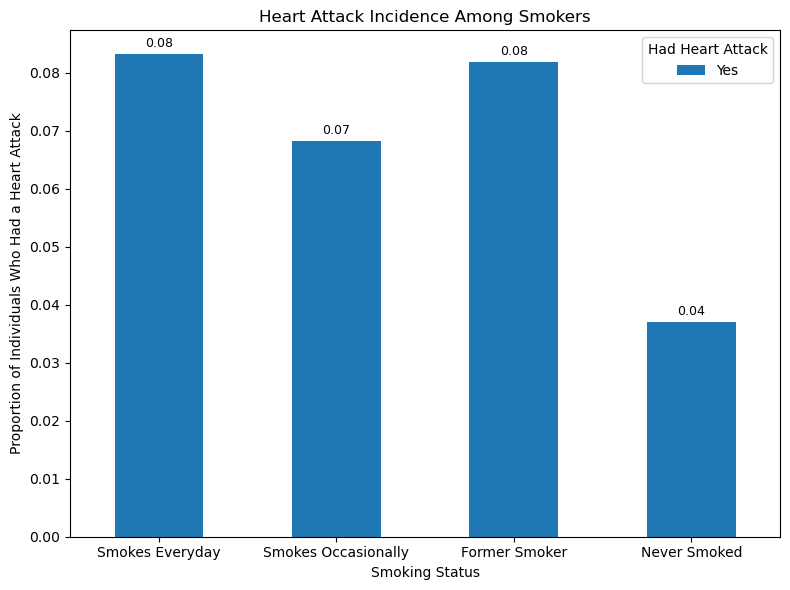

In [4]:
#Lifestyle

# SMOKING 
category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["SmokerStatus"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["Smokes Everyday","Smokes Occasionally", "Former Smoker", "Never Smoked", ], rotation=0)

x.set_xlabel("Smoking Status")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Incidence Among Smokers")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()



In [4]:
#BMI
plt.figure(figsize=(8,6))
sns.boxplot(x='HadHeartAttack', y='BMI', data= cdc_survey_data)
plt.title('BMI vs Heart Attack')
plt.show()

NameError: name 'cdc_survey_data' is not defined

<Figure size 800x600 with 0 Axes>

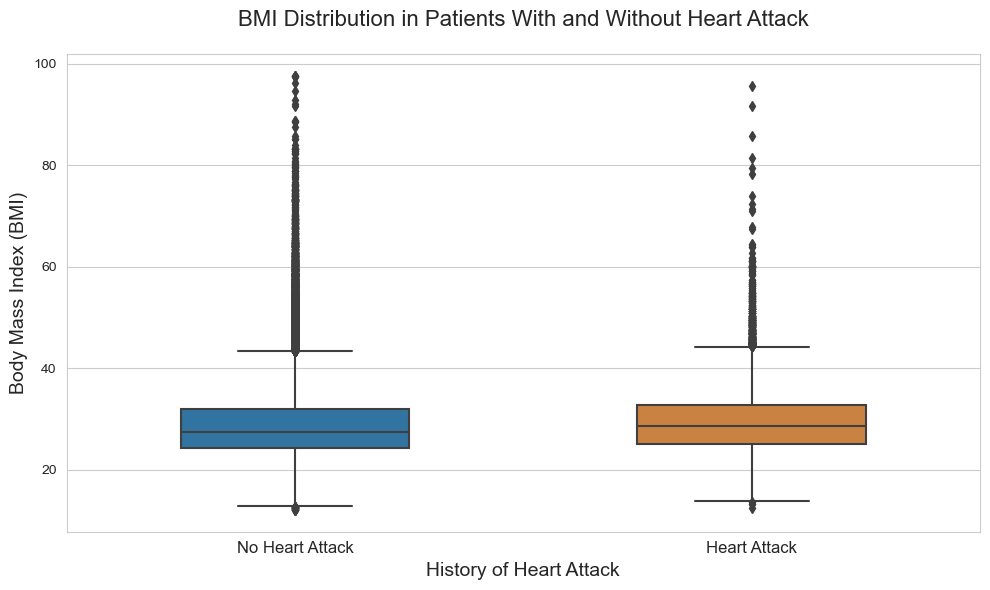

In [6]:
#BMI
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Create an improved boxplot
ax = sns.boxplot(x="HadHeartAttack", y="BMI", 
                data=cdc_survey_data,  
                palette=["#1f77b4", "#E1812C"],
                width=0.5,
               )



plt.title("BMI Distribution in Patients With and Without Heart Attack", fontsize=16, pad=20)
plt.xlabel("History of Heart Attack", fontsize=14)
plt.ylabel("Body Mass Index (BMI)", fontsize=14)

plt.xticks([0, 1], ["No Heart Attack", "Heart Attack"], fontsize=12)




plt.tight_layout()
plt.show()


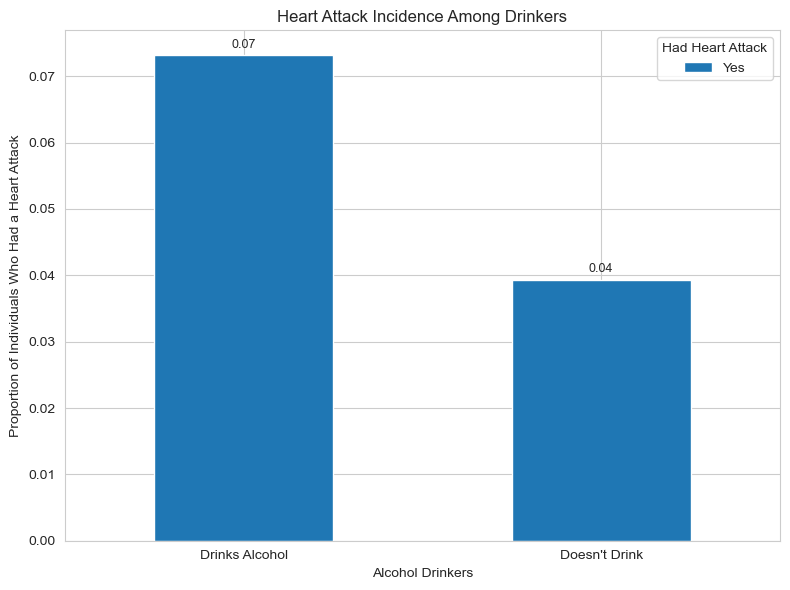

In [7]:
#ALCHOL 
category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["AlcoholDrinkers"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["Drinks Alcohol", "Doesn't Drink", ], rotation=0)

x.set_xlabel("Alcohol Drinkers")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Incidence Among Drinkers")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()




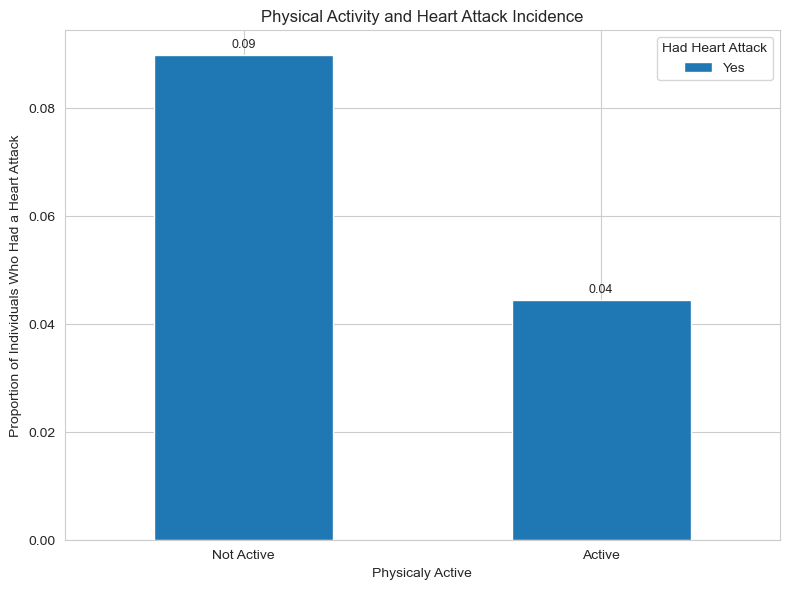

In [8]:
#Physical Activities
category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["PhysicalActivities"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["Not Active", "Active", ], rotation=0)

x.set_xlabel("Physicaly Active")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Physical Activity and Heart Attack Incidence")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()



C:\Users\yusuf\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\yusuf\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\yusuf\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


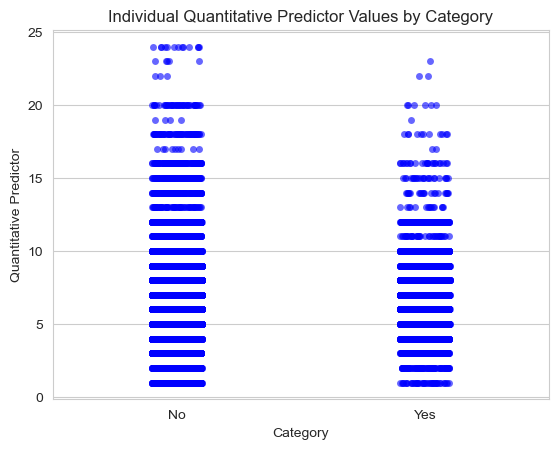

In [9]:
sns.stripplot(x='HadHeartAttack', y='SleepHours', data=cdc_survey_data, jitter=True, color='blue', alpha=0.6)

plt.title('Individual Quantitative Predictor Values by Category')
plt.xlabel('Category')
plt.ylabel('Quantitative Predictor')
plt.show()

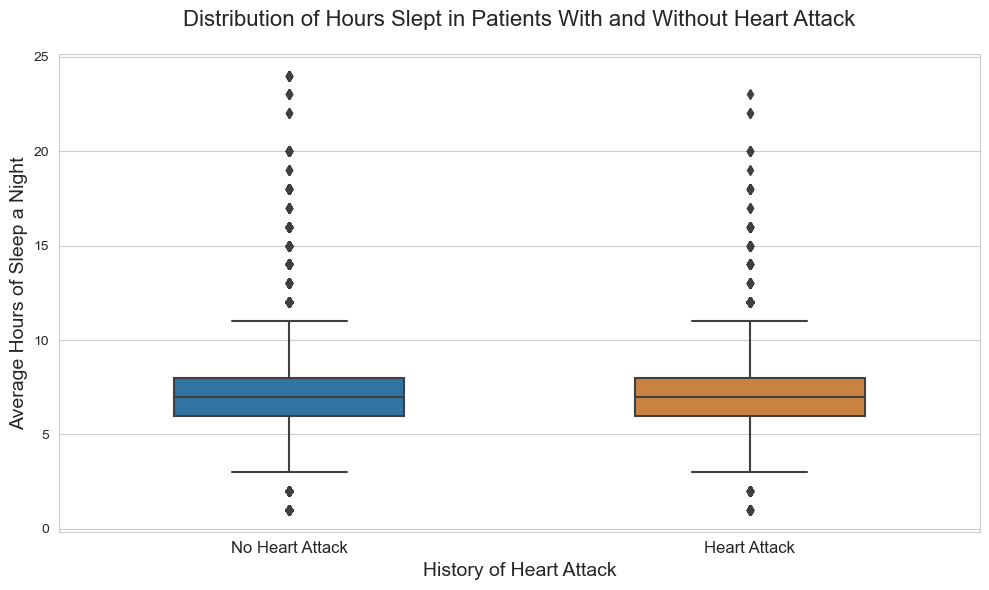

In [10]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Create an improved boxplot
ax = sns.boxplot(x="HadHeartAttack", y="SleepHours", 
                data=cdc_survey_data,  
                palette=["#1f77b4", "#E1812C"],
                width=0.5,
               )



plt.title("Distribution of Hours Slept in Patients With and Without Heart Attack", fontsize=16, pad=20)
plt.xlabel("History of Heart Attack", fontsize=14)
plt.ylabel("Average Hours of Sleep a Night", fontsize=14)

plt.xticks([0, 1], ["No Heart Attack", "Heart Attack"], fontsize=12)




plt.tight_layout()
plt.show()

In [11]:
predictor = cdc_survey_data["SleepHours"]
outcome = cdc_survey_data["HadHeartAttack"]

heart_attack_binary = [1 if val.lower() == 'yes' else 0 for val in outcome]
correlation, p_value = pointbiserialr(heart_attack_binary, predictor)

print("Point-Biserial Correlation:", correlation)
print("P-value:", p_value)

Point-Biserial Correlation: 0.0036309227895033273
P-value: 0.07170974440857596


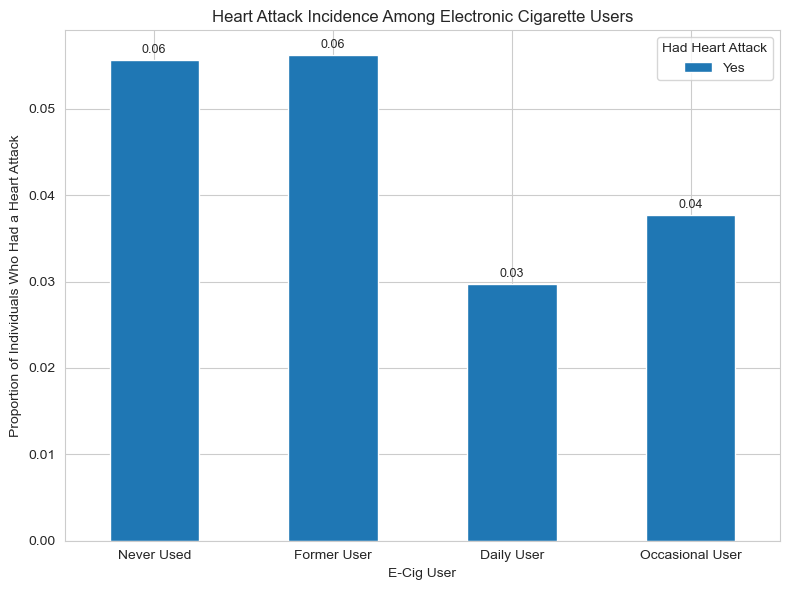

In [12]:
# ECig
category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["ECigaretteUsage"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["Never Used","Former User", "Daily User", "Occasional User", ], rotation=0)

x.set_xlabel("E-Cig User")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Incidence Among Electronic Cigarette Users")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

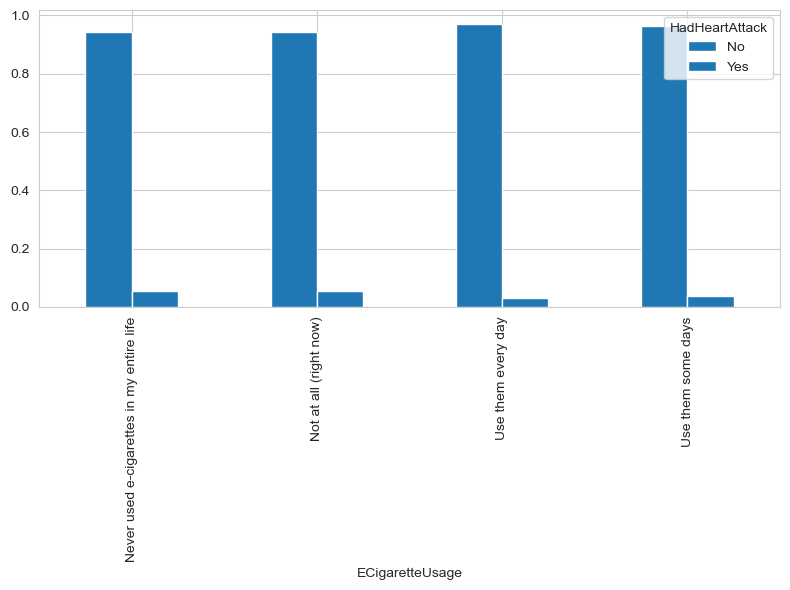

In [13]:

crosstab = pd.crosstab(cdc_survey_data["ECigaretteUsage"], cdc_survey_data["HadHeartAttack"], normalize="index") 


x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))


plt.tight_layout()
plt.show()

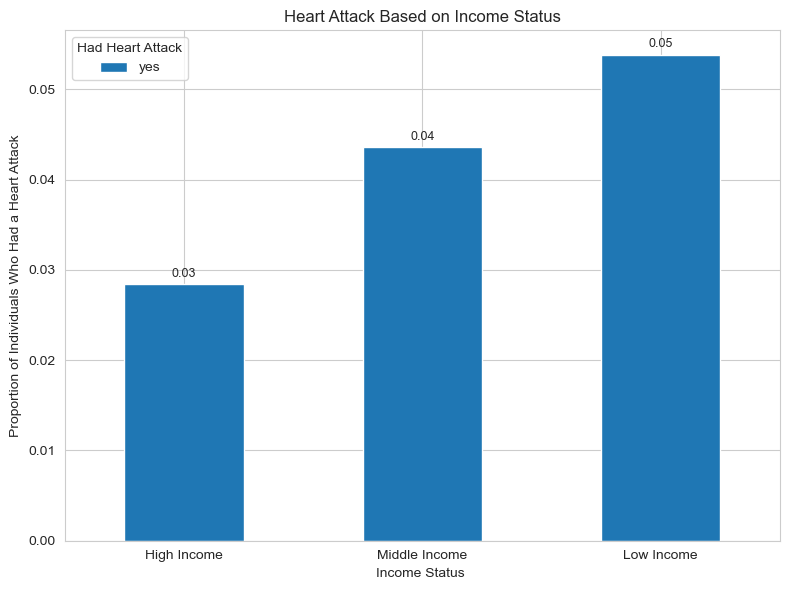

In [14]:
# Socioeconomic Status
desired_order = ["high income", "middle income","low income"]
crosstab = pd.crosstab(BRFSS_survey["PIR"], BRFSS_survey["heart.attack"], normalize="index") 
crosstab = crosstab.loc[desired_order]

category_order = ["yes"]
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["High Income","Middle Income", "Low Income"], rotation=0)

x.set_xlabel("Income Status ")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Based on Income Status")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


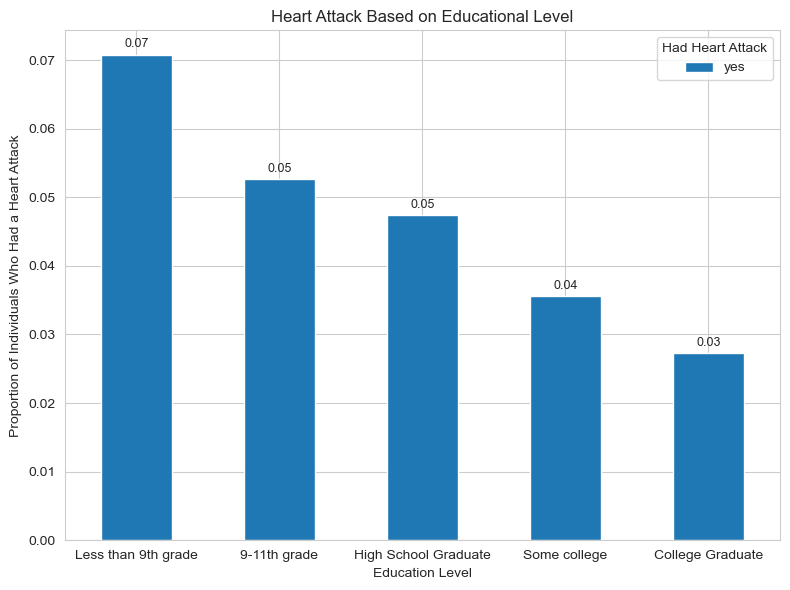

In [15]:
desired_order = ["less than 9th grade","9-11th grade", "high school graduate","some college or AA degree","college graduate or above"]
crosstab = pd.crosstab(BRFSS_survey["edu"], BRFSS_survey["heart.attack"], normalize="index") 
crosstab = crosstab.loc[desired_order]

category_order = ["yes"]
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["Less than 9th grade","9-11th grade", "High School Graduate","Some college", "College Graduate" ], rotation=0)

x.set_xlabel("Education Level")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Based on Educational Level")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


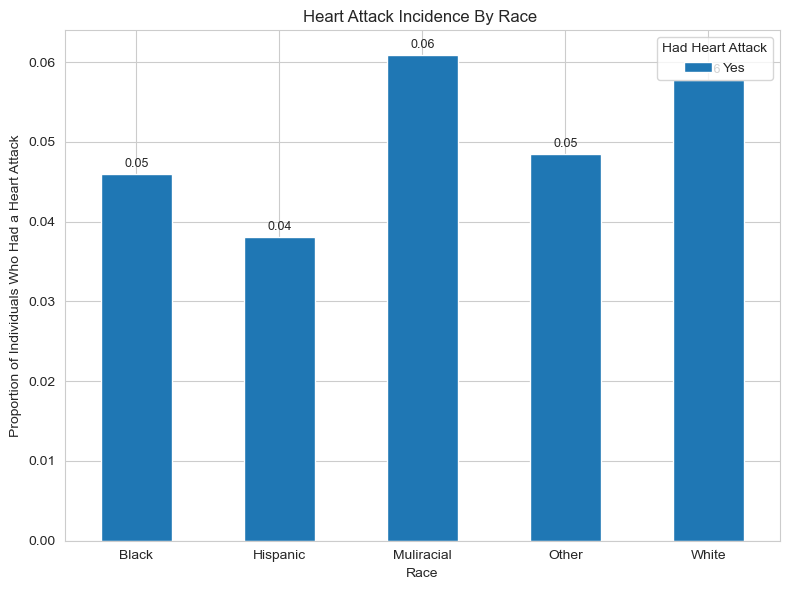

In [16]:

category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["RaceEthnicityCategory"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["Black","Hispanic", "Muliracial", "Other","White" ], rotation=0)

x.set_xlabel("Race")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Incidence By Race ")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

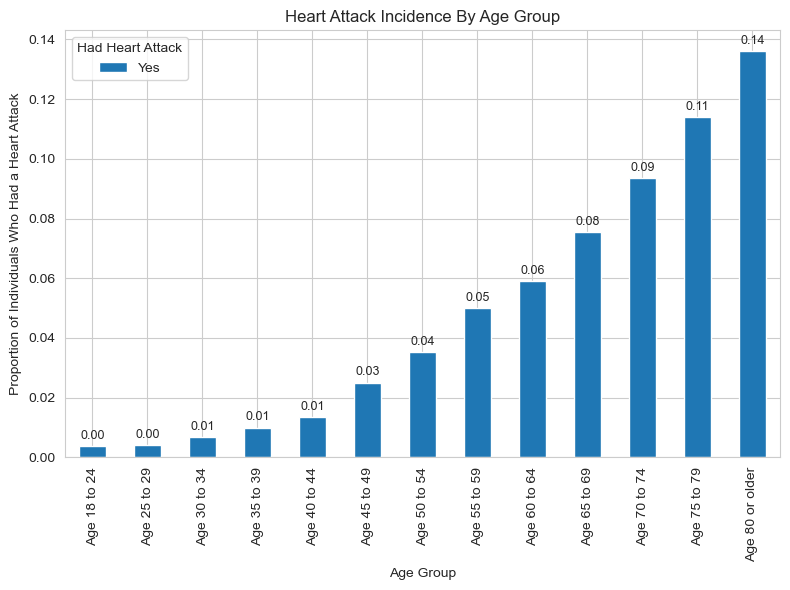

In [17]:
# Features 

#Age 
category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["AgeCategory"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))


x.set_xlabel("Age Group")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Incidence By Age Group")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()



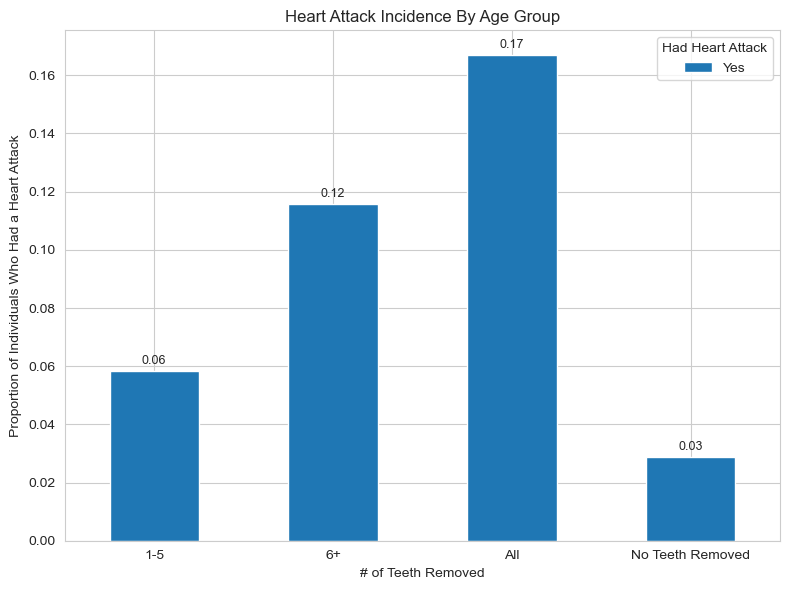

In [18]:
# Teeth Removal 
category_order = ["Yes"]
crosstab = pd.crosstab(cdc_survey_data["RemovedTeeth"], cdc_survey_data["HadHeartAttack"], normalize="index") 
crosstab = crosstab[category_order]

x = crosstab.plot(kind="bar", stacked=False,color="#1f77b4", figsize=(8,6))
x. set_xticklabels(["1-5","6+", "All", "No Teeth Removed", ], rotation=0)

x.set_xlabel("# of Teeth Removed")
x.set_ylabel("Proportion of Individuals Who Had a Heart Attack")
x.set_title("Heart Attack Incidence By Age Group")
x.legend(title="Had Heart Attack")

for bar in x.patches:
    height = bar.get_height()
    x.annotate(f"{height:.2f}", 
               xy=(bar.get_x() + bar.get_width() / 2, height),
               xytext=(0, 3), 
               textcoords="offset points",
               ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()



In [19]:
disease_data = pd.read_csv("Cardiovascular_Disease_Dataset.csv")

print(disease_data.head())

   patientid  age  gender  chestpain  restingBP  serumcholestrol  \
0     103368   53       1          2        171                0   
1     119250   40       1          0         94              229   
2     119372   49       1          2        133              142   
3     132514   43       1          0        138              295   
4     146211   31       1          1        199                0   

   fastingbloodsugar  restingrelectro  maxheartrate  exerciseangia  oldpeak  \
0                  0                1           147              0      5.3   
1                  0                1           115              0      3.7   
2                  0                0           202              1      5.0   
3                  1                1           153              0      3.2   
4                  0                2           136              0      5.3   

   slope  noofmajorvessels  target  
0      3                 3       1  
1      1                 1       0  
2    

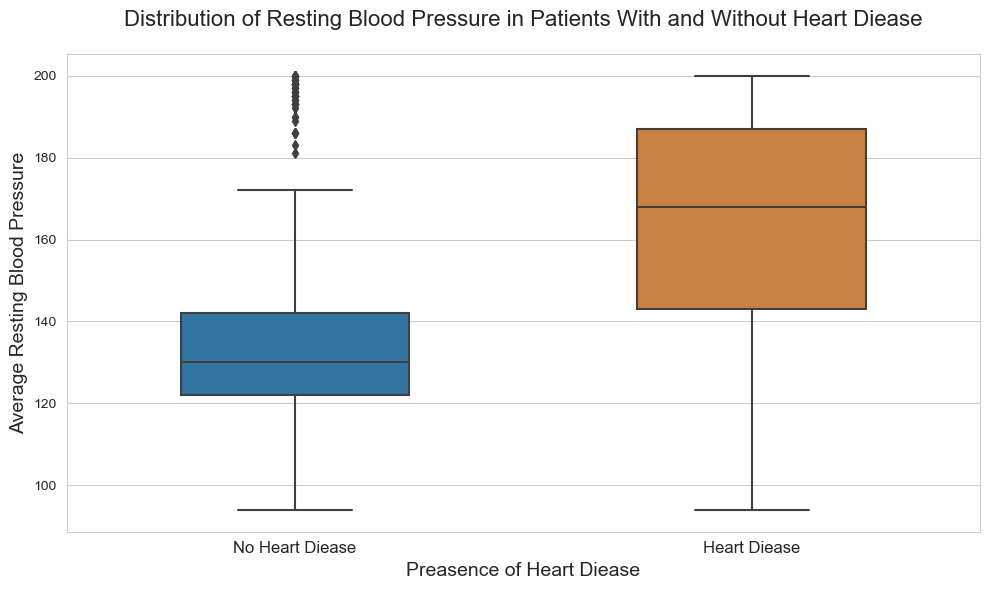

In [20]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Create an improved boxplot
ax = sns.boxplot(x="target", y="restingBP", 
                data=disease_data,  
                palette=["#1f77b4", "#E1812C"],
                width=0.5,
               )



plt.title("Distribution of Resting Blood Pressure in Patients With and Without Heart Diease", fontsize=16, pad=20)
plt.xlabel("Preasence of Heart Diease", fontsize=14)
plt.ylabel("Average Resting Blood Pressure", fontsize=14)

plt.xticks([0, 1], ["No Heart Diease", "Heart Diease"], fontsize=12)




plt.tight_layout()
plt.show()

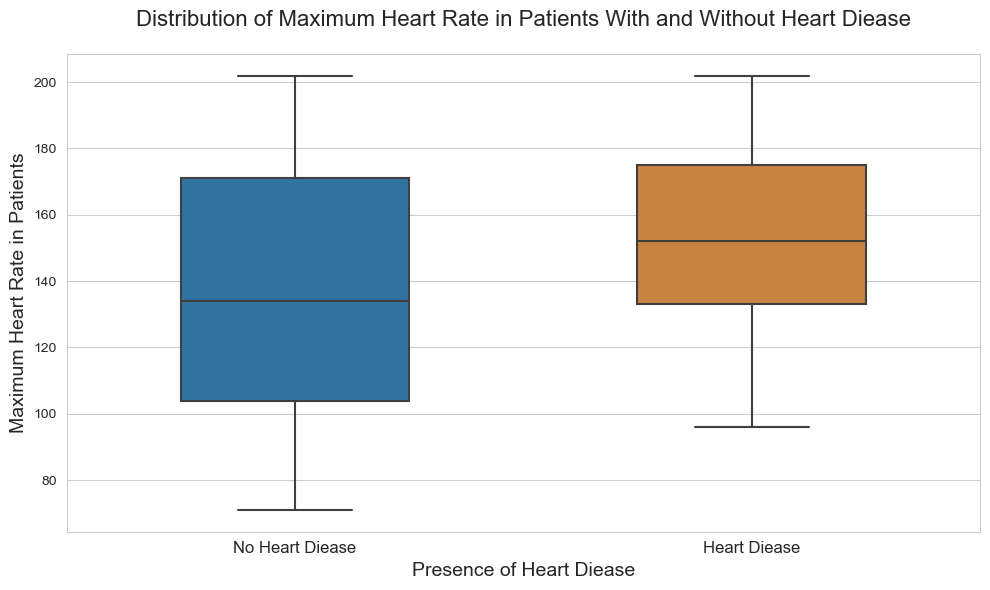

In [21]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Create an improved boxplot
ax = sns.boxplot(x="target", y="maxheartrate", 
                data=disease_data,  
                palette=["#1f77b4", "#E1812C"],
                width=0.5,
               )



plt.title("Distribution of Maximum Heart Rate in Patients With and Without Heart Diease", fontsize=16, pad=20)
plt.xlabel("Presence of Heart Diease", fontsize=14)
plt.ylabel("Maximum Heart Rate in Patients", fontsize=14)

plt.xticks([0, 1], ["No Heart Diease", "Heart Diease"], fontsize=12)




plt.tight_layout()
plt.show()

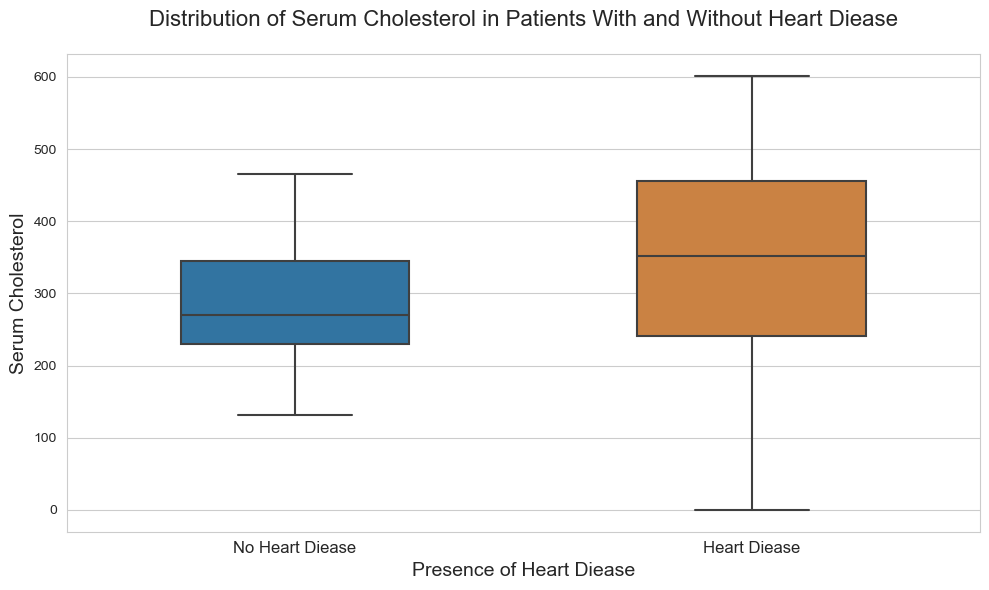

In [22]:
#Serum Cholesterol amount of cholesterol in blood 

plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Create an improved boxplot
ax = sns.boxplot(x="target", y="serumcholestrol", 
                data=disease_data,  
                palette=["#1f77b4", "#E1812C"],
                width=0.5,
               )



plt.title("Distribution of Serum Cholesterol in Patients With and Without Heart Diease", fontsize=16, pad=20)
plt.xlabel("Presence of Heart Diease", fontsize=14)
plt.ylabel("Serum Cholesterol", fontsize=14)

plt.xticks([0, 1], ["No Heart Diease", "Heart Diease"], fontsize=12)




plt.tight_layout()
plt.show()

In [23]:
# Random Forest Classifier

cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']

from sklearn.model_selection import train_test_split

predictors_train, predictors_test, target_train, target_test = train_test_split(predictors, target, test_size=0.2, random_state=42)#80/20 training test split

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100,class_weight='balanced', random_state=42)
model.fit(predictors_train, target_train)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

target_pred = model.predict(predictors_test)

print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))


Accuracy: 0.9483182603393964
Confusion Matrix:
 [[46372   201]
 [ 2342   290]]
Classification Report:
               precision    recall  f1-score   support

       False       0.95      1.00      0.97     46573
        True       0.59      0.11      0.19      2632

    accuracy                           0.95     49205
   macro avg       0.77      0.55      0.58     49205
weighted avg       0.93      0.95      0.93     49205



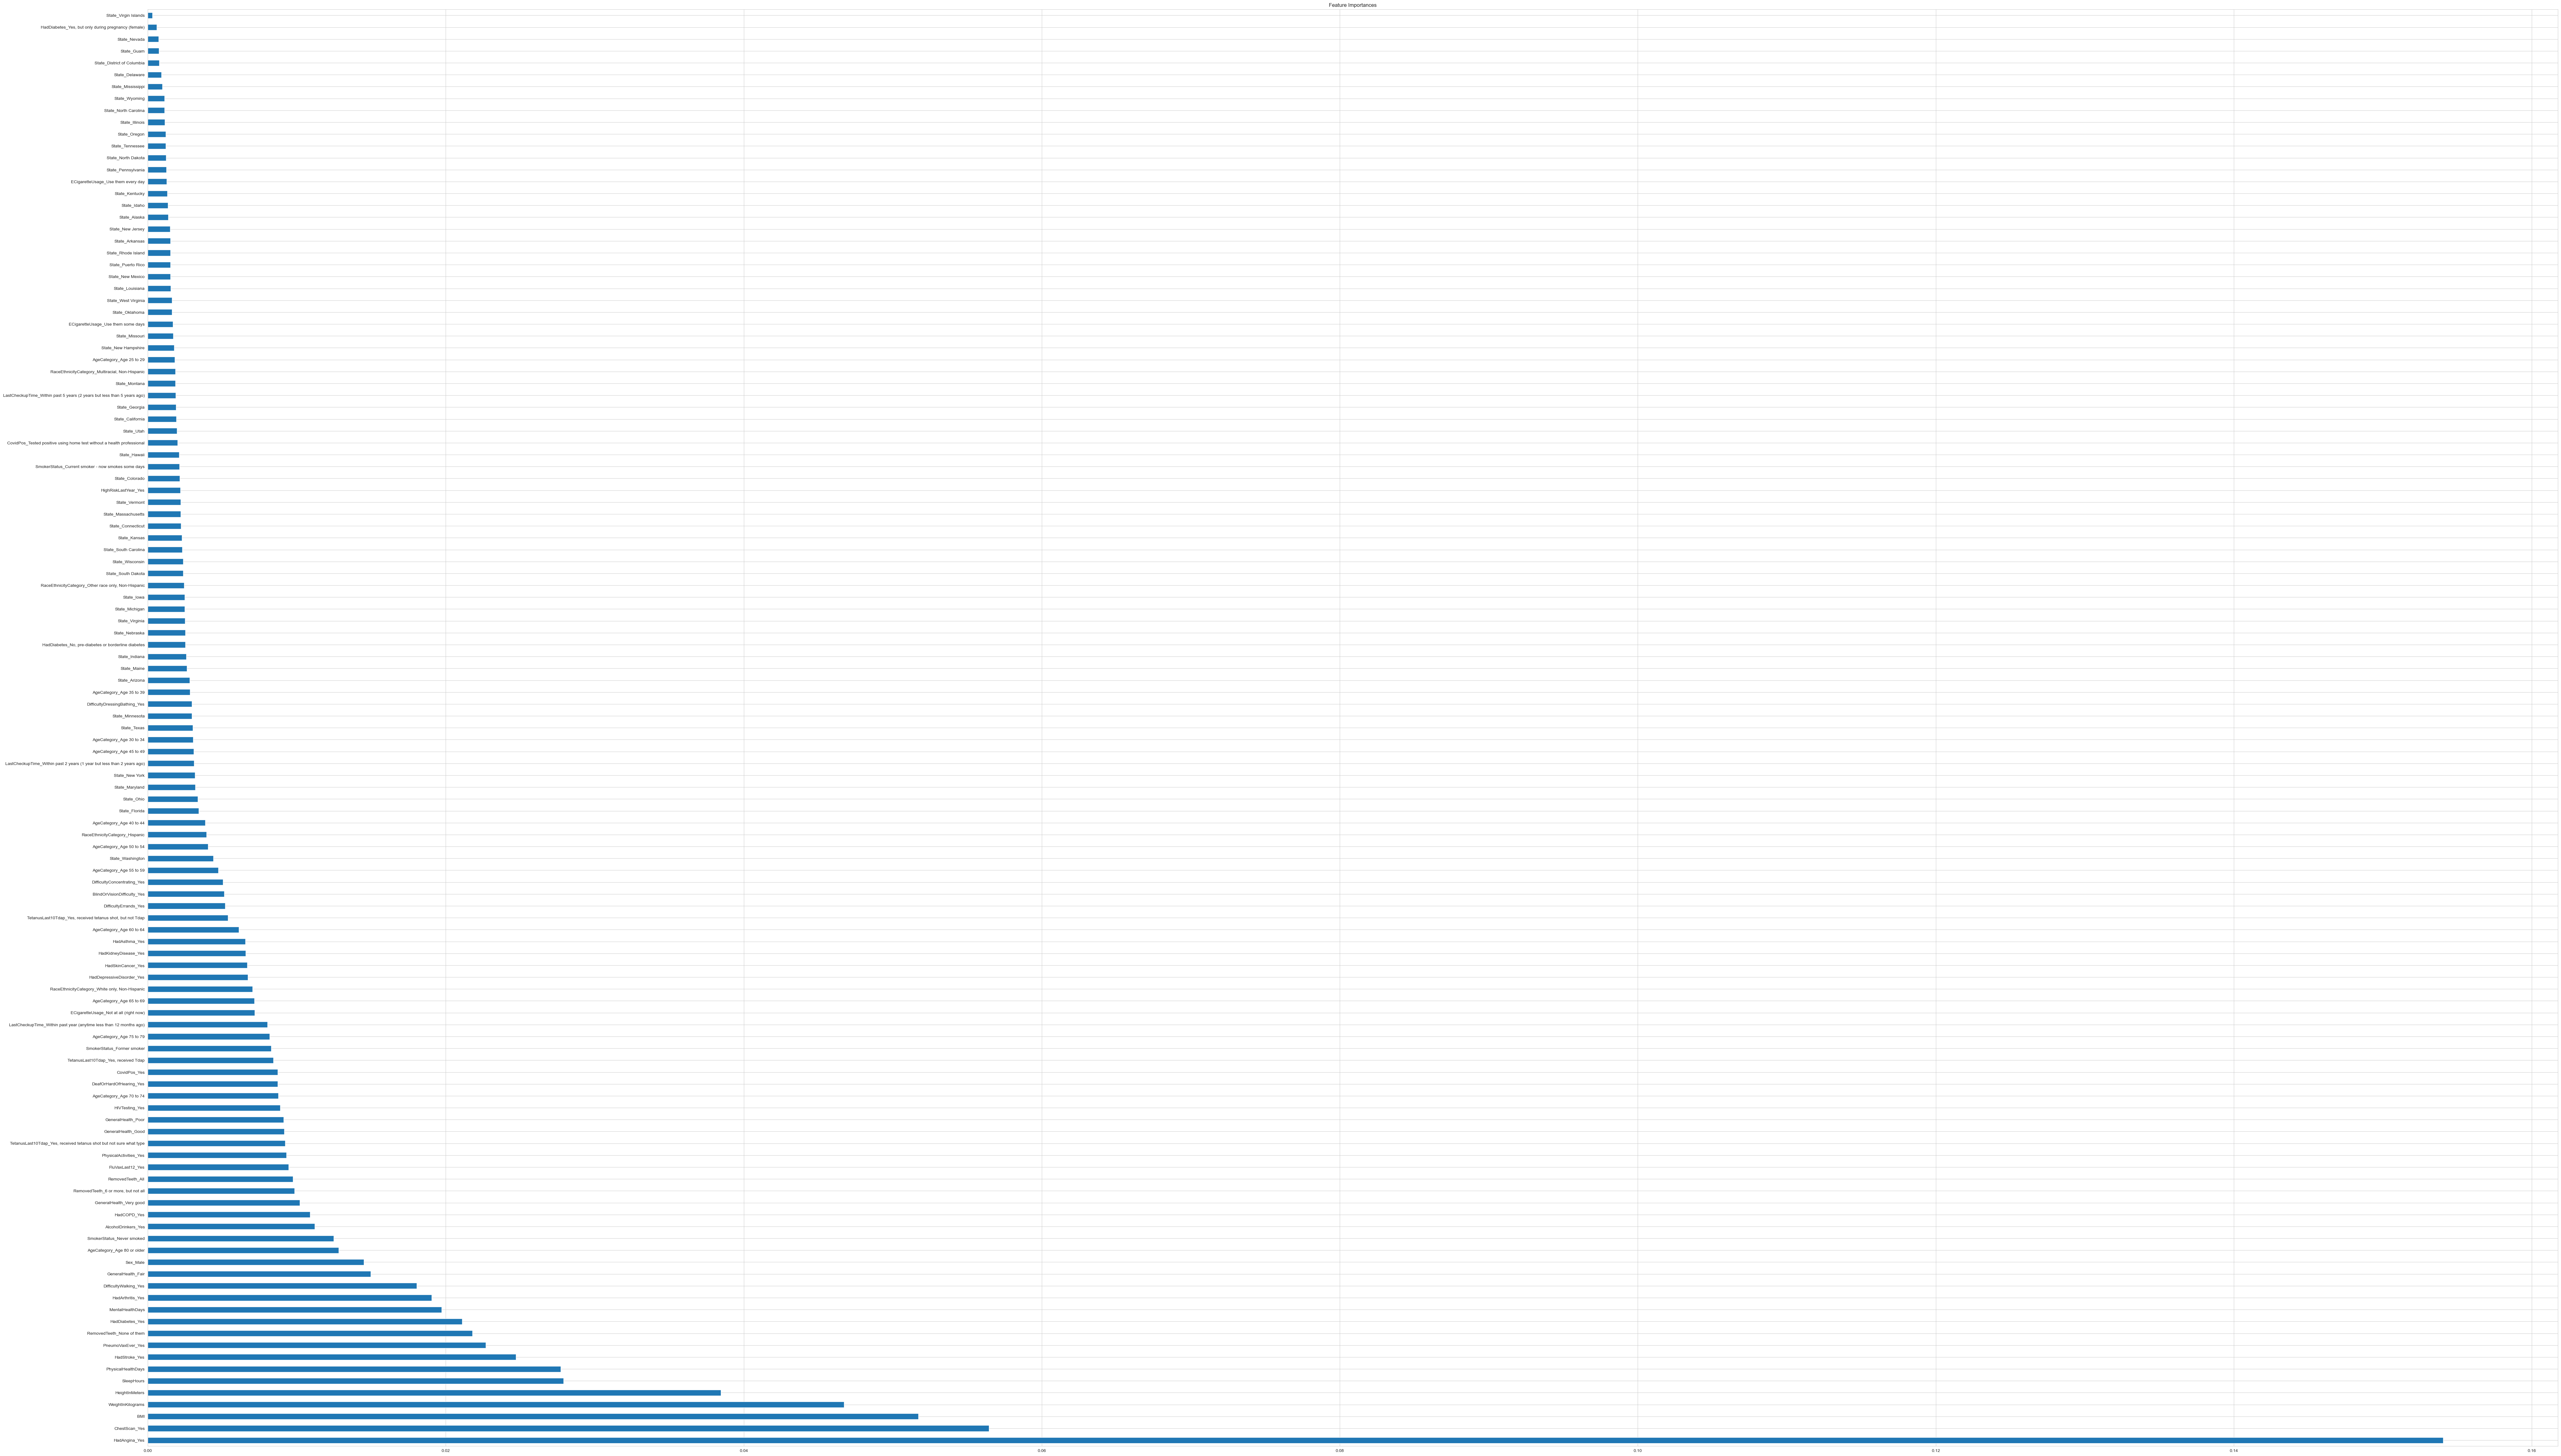

In [24]:
# Get imoratnace of feautres 
importances = pd.Series(model.feature_importances_, index=predictors.columns)
importances.sort_values(ascending=False).plot(kind='barh', figsize=(100, 60))
plt.title("Feature Importances")
plt.show()

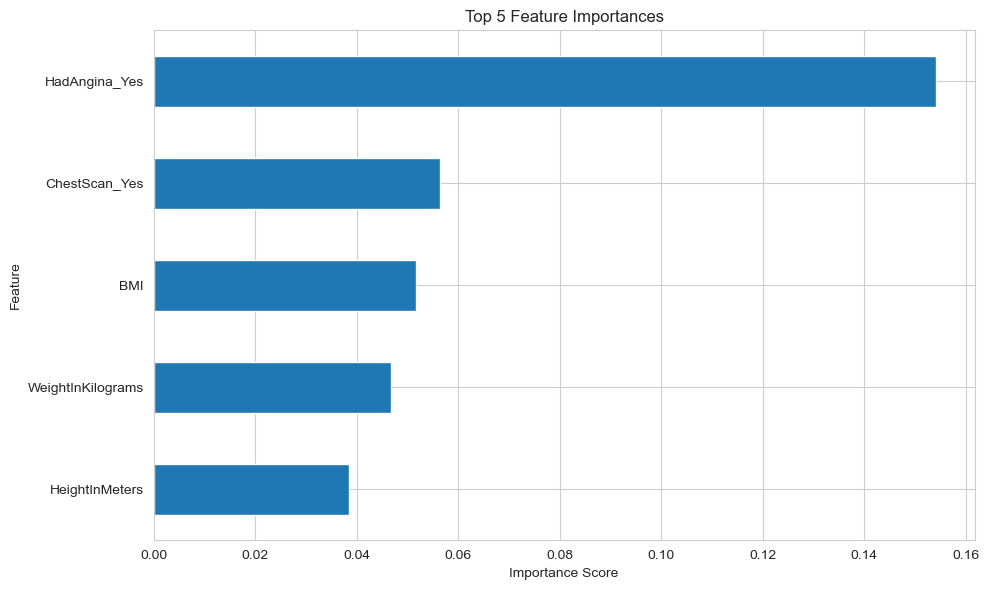

In [25]:
import pandas as pd
import matplotlib.pyplot as plt


importances = pd.Series(model.feature_importances_, index=predictors.columns)

sorted_importances = importances.sort_values(ascending=False)

top_5_importances = sorted_importances.head(5)

top_5_importances.sort_values(ascending=True).plot(
    kind='barh',
    figsize=(10, 6)
)


plt.title("Top 5 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [26]:
cdc_encoded

,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI,State_Alaska,State_Arizona,State_Arkansas,State_California,...,AlcoholDrinkers_Yes,HIVTesting_Yes,FluVaxLast12_Yes,PneumoVaxEver_Yes,"TetanusLast10Tdap_Yes, received Tdap","TetanusLast10Tdap_Yes, received tetanus shot but not sure what type","TetanusLast10Tdap_Yes, received tetanus shot, but not Tdap",HighRiskLastYear_Yes,CovidPos_Tested positive using home test without a health professional,CovidPos_Yes
0,4,0,9,1.60,71.67,27.99,False,False,False,False,...,False,False,True,True,True,False,False,False,False,False
1,0,0,6,1.78,95.25,30.13,False,False,False,False,...,False,False,True,True,False,True,False,False,False,False
2,0,0,8,1.85,108.86,31.66,False,False,False,False,...,True,False,False,True,False,False,False,False,False,True
3,5,0,9,1.70,90.72,31.32,False,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,3,15,5,1.55,79.38,33.07,False,False,False,False,...,False,False,True,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246017,0,0,6,1.78,102.06,32.28,False,False,False,False,...,True,False,False,False,False,True,False,False,False,False
246018,0,7,7,1.93,90.72,24.34,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
246019,0,15,7,1.68,83.91,29.86,False,False,False,False,...,True,True,True,True,False,True,False,False,False,True
246020,2,2,7,1.70,83.01,28.66,False,False,False,False,...,False,True,True,False,False,True,False,False,False,False


In [27]:
# get values at diffrent threshlods 

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score
import numpy as np

cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']

# 80/20
predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(predictors_train, target_train)

target_pred_proba = model.predict_proba(predictors_test)[:,1]

# Try different thresholds
thresholds = np.arange(0.1, 0.6, 0.1)  # 0.1 to 0.5
for t in thresholds:
    target_pred = (target_pred_proba >= t).astype(int)
    recall = recall_score(target_test, target_pred)
    tn, fp, fn, tp = confusion_matrix(target_test, target_pred).ravel()
    print(f"Threshold: {t:.1f} | Recall (Positive Class): {recall:.2f} | Type I (FP): {fp} | Type II (FN): {fn}")


chosen_threshold = 0.1
target_pred = (target_pred_proba >= chosen_threshold).astype(int)
print("\n--- Metrics at Threshold 0.1 ---")
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))


Threshold: 0.1 | Recall (Positive Class): 0.68 | Type I (FP): 5073 | Type II (FN): 855
Threshold: 0.2 | Recall (Positive Class): 0.52 | Type I (FP): 1899 | Type II (FN): 1267
Threshold: 0.3 | Recall (Positive Class): 0.41 | Type I (FP): 1136 | Type II (FN): 1541
Threshold: 0.4 | Recall (Positive Class): 0.28 | Type I (FP): 655 | Type II (FN): 1900
Threshold: 0.5 | Recall (Positive Class): 0.13 | Type I (FP): 230 | Type II (FN): 2296

--- Metrics at Threshold 0.1 ---
Accuracy: 0.8795244385733157
Confusion Matrix:
 [[41500  5073]
 [  855  1777]]
Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.89      0.93     46573
        True       0.26      0.68      0.37      2632

    accuracy                           0.88     49205
   macro avg       0.62      0.78      0.65     49205
weighted avg       0.94      0.88      0.90     49205



In [28]:
# Type 2 error due to data imbalance


cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']

from sklearn.model_selection import train_test_split

predictors_train, predictors_test, target_train, target_test = train_test_split(predictors, target, test_size=0.2, random_state=42)#80/20 training test split

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,          
    max_depth=None,            
    min_samples_split=2,       
    class_weight={0:1, 1:10},  # ten times weight for the postive class
    random_state=42
)
model.fit(predictors_train, target_train)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

target_pred = model.predict(predictors_test)

print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))

Accuracy: 0.9484808454425363
Confusion Matrix:
 [[46361   212]
 [ 2323   309]]
Classification Report:
               precision    recall  f1-score   support

       False       0.95      1.00      0.97     46573
        True       0.59      0.12      0.20      2632

    accuracy                           0.95     49205
   macro avg       0.77      0.56      0.58     49205
weighted avg       0.93      0.95      0.93     49205



In [29]:
# Threshold + Class Weights
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score
import numpy as np


cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']


predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42
)


model = RandomForestClassifier(
    n_estimators=150,            
    max_depth=15,                
    class_weight={0:1, 1:8},    
    random_state=42
)
model.fit(predictors_train, target_train)


target_pred_proba = model.predict_proba(predictors_test)[:,1]


chosen_threshold = 0.1
target_pred = (target_pred_proba >= chosen_threshold).astype(int)

print(f"--- Metrics at Threshold {chosen_threshold} ---")
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Recall (Positive Class):", recall_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))
# Fixes type 2 error but creates a lot of type 1 error

--- Metrics at Threshold 0.1 ---
Accuracy: 0.4865155980083325
Recall (Positive Class): 0.9604863221884499
Confusion Matrix:
 [[21411 25162]
 [  104  2528]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.46      0.63     46573
        True       0.09      0.96      0.17      2632

    accuracy                           0.49     49205
   macro avg       0.54      0.71      0.40     49205
weighted avg       0.95      0.49      0.60     49205



In [30]:
# Threshold + Class Weights
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score
import numpy as np


cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']


predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42
)


model = RandomForestClassifier(
    n_estimators=150,            
    max_depth=15,                
    class_weight={0:1, 1:4},    
    random_state=42
)
model.fit(predictors_train, target_train)


target_pred_proba = model.predict_proba(predictors_test)[:,1]


chosen_threshold = 0.25
target_pred = (target_pred_proba >= chosen_threshold).astype(int)

print(f"--- Metrics at Threshold {chosen_threshold} ---")
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Recall (Positive Class):", recall_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))
# Fixes type 2 error but creates a lot of type 1 error

--- Metrics at Threshold 0.25 ---
Accuracy: 0.9088913728279646
Recall (Positive Class): 0.6223404255319149
Confusion Matrix:
 [[43084  3489]
 [  994  1638]]
Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.93      0.95     46573
        True       0.32      0.62      0.42      2632

    accuracy                           0.91     49205
   macro avg       0.65      0.77      0.69     49205
weighted avg       0.94      0.91      0.92     49205



In [33]:
#SMOTE
# syntetic data points
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd


cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']

# Split
predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42
)

# SMOTE on the training
sm = SMOTE(random_state=42)
predictors_train_res, target_train_res = sm.fit_resample(predictors_train, target_train)

#print("Before SMOTE:", target_train.value_counts())
#print("After SMOTE:", target_train_res.value_counts())

# Train the model
model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced_subsample',
    random_state=42
)
model.fit(predictors_train_res, target_train_res)

# Predict
target_pred = model.predict(predictors_test)

# Evaluate
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))
# 47% true class

Accuracy: 0.9439691088304034
Confusion Matrix:
 [[45390  1183]
 [ 1574  1058]]
Classification Report:
               precision    recall  f1-score   support

       False       0.97      0.97      0.97     46573
        True       0.47      0.40      0.43      2632

    accuracy                           0.94     49205
   macro avg       0.72      0.69      0.70     49205
weighted avg       0.94      0.94      0.94     49205



In [13]:
# Old method was using one hot encoding making seprate predcitive varibles (o or 1)
# Risk based method gives weights based on how genhealth correlates based on this dataset
# How likly each group is to have heart diease

cdc_survey_data['HadHeartAttack_Yes'] = (cdc_survey_data['HadHeartAttack'] == "Yes")
genhealth_risks = cdc_survey_data.groupby('GeneralHealth')['HadHeartAttack_Yes'].mean()
print(genhealth_risks)

GeneralHealth
Excellent    0.014305
Fair         0.122248
Good         0.059412
Poor         0.214634
Very good    0.028391
Name: HadHeartAttack_Yes, dtype: float64


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

risk_map = genhealth_risks.to_dict()
cdc_survey_data['GenHealth_score'] = cdc_survey_data['GeneralHealth'].map(risk_map)

target = cdc_survey_data['HadHeartAttack_Yes']  
predictors = cdc_survey_data.drop(['HadHeartAttack_Yes', 'GeneralHealth', 'HadHeartAttack'], axis=1)
predictors_encoded = pd.get_dummies(predictors, drop_first=True)



X_train, X_test, y_train, y_test = train_test_split(
    predictors_encoded, target, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)  

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))



Accuracy: 0.9476679199268367
Confusion Matrix:
 [[46363   210]
 [ 2365   267]]
Classification Report:
               precision    recall  f1-score   support

       False       0.95      1.00      0.97     46573
        True       0.56      0.10      0.17      2632

    accuracy                           0.95     49205
   macro avg       0.76      0.55      0.57     49205
weighted avg       0.93      0.95      0.93     49205



In [25]:
import pandas as pd

# Get feature importances from the trained model
importances = model.feature_importances_

# Map them to the column names
feature_importance_df = pd.DataFrame({
    'feature': predictors_encoded.columns,
    'importance': importances
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)
print(feature_importance_df.head(10))

                      feature  importance
68              HadAngina_Yes    0.153387
5                         BMI    0.051406
91              ChestScan_Yes    0.049968
6             GenHealth_score    0.047462
4           WeightInKilograms    0.046885
3              HeightInMeters    0.038434
0          PhysicalHealthDays    0.028325
2                  SleepHours    0.028311
67  RemovedTeeth_None of them    0.022608
69              HadStroke_Yes    0.021685


In [ ]:
 # -Feature Selection with CFS Subset Evaluation with Best-First-Search

KeyError: "['HadHeartAttack_Yes'] not found in axis"

In [ ]:
# refrence 2 
